# Assignment 2: Data Mining, Modelling and Analytics
## Project 2: Credit Card Fraud Detection

### Objective
To investigate credit card transaction patterns, identify potentially
fraudulent transactions using anomaly detection techniques, and
evaluate their effectiveness on highly imbalanced transaction data.

### 1. Exploratory Data Analysis and Data Preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)

sns.set_theme(style="whitegrid")

In [2]:
# Loading the dataset
df = pd.read_csv("creditcard.csv")

# Examining dataset dimensions
print("Dataset shape:", df.shape)

# Display the first five transactions
display(df.head())

# Examining variable types
print("\nDataset information:")
df.info()

# Checking missing values
print("\nMissing values:")
display(df.isnull().sum())

# Checking duplicate transactions
print("\nDuplicate observations:", df.duplicated().sum())

# Examining fraud distribution
print("\nTransaction classification:")
display(df["Class"].value_counts())

print("\nClass distribution (%):")
display((df["Class"].value_counts(normalize=True) * 100).round(4))

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  f

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


Duplicate observations: 1081

Transaction classification:


Class
0    284315
1       492
Name: count, dtype: int64


Class distribution (%):


Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64

### 1.1 Dataset Overview and Initial Data Quality Assessment

The dataset contains 284,807 credit card transactions and 31 variables, comprising 30 numerical predictors and one binary fraud indicator (Class). The predictors include 28 anonymized principal components (V1–V28), transaction Time, and Amount. Initial inspection identified no missing values but revealed 1,081 duplicate observations.

The dataset is highly imbalanced, with 284,315 legitimate transactions (99.8273%) and only 492 fraudulent transactions (0.1727%). Consequently, conventional accuracy is unsuitable as the primary evaluation measure because a model predicting every transaction as legitimate would achieve approximately 99.83% accuracy without identifying any fraud.

Duplicate observations will initially be retained pending further investigation, as they may represent repeated transactions rather than data-entry errors. The analysis will prioritize anomaly ranking and evaluation measures appropriate for rare events, particularly precision, recall, and average precision.

Duplicate observations by transaction class:


,Duplicate Records,Total Records,Duplicate Rate (%)
Class,,,
0,1062,284315,0.373529
1,19,492,3.861789



Transaction Time and Amount:


,Time,Amount
count,284807.00,284807.00
mean,94813.86,88.35
std,47488.15,250.12
min,0.00,0.00
25%,54201.50,5.60
50%,84692.00,22.00
75%,139320.50,77.16
max,172792.00,25691.16


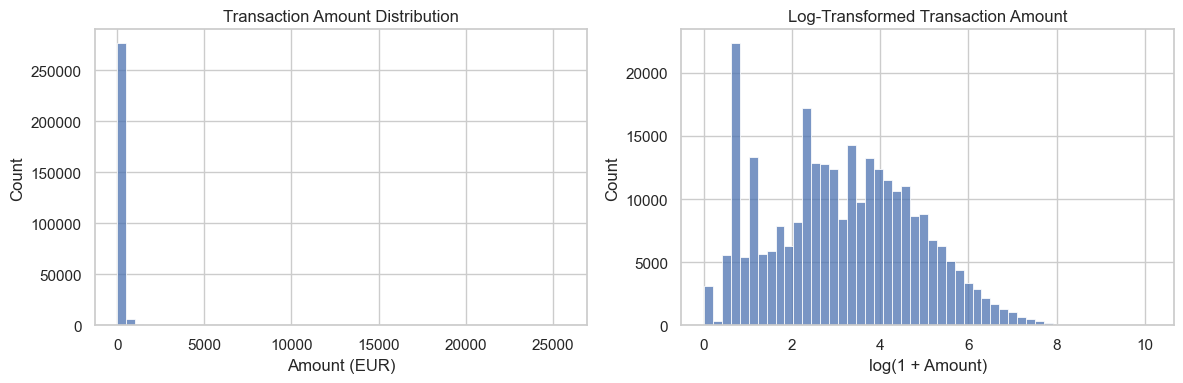

In [3]:
# Examining duplicate transactions by fraud class

duplicates = df.duplicated(keep="first")

duplicate_summary = pd.DataFrame({
    "Duplicate Records": df.loc[duplicates, "Class"].value_counts(),
    "Total Records": df["Class"].value_counts()
}).fillna(0).astype(int)

duplicate_summary["Duplicate Rate (%)"] = (
    duplicate_summary["Duplicate Records"]
    / duplicate_summary["Total Records"] * 100
)

print("Duplicate observations by transaction class:")
display(duplicate_summary)


# Descriptive statistics for Time and Amount

print("\nTransaction Time and Amount:")
display(df[["Time", "Amount"]].describe().round(2))


# Examine transaction amount distribution

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    df["Amount"],
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Transaction Amount Distribution")
axes[0].set_xlabel("Amount (EUR)")


sns.histplot(
    np.log1p(df["Amount"]),
    bins=50,
    ax=axes[1]
)

axes[1].set_title("Log-Transformed Transaction Amount")
axes[1].set_xlabel("log(1 + Amount)")

plt.tight_layout()
plt.show()

### 1.2 Duplicate Analysis and Transaction Amount Distribution

Duplicate analysis identified 1,081 repeated observations, comprising 1,062 legitimate and 19 fraudulent transactions. The duplicate rate was substantially higher among fraudulent transactions (3.86%) than legitimate transactions (0.37%). However, identical records cannot automatically be considered data-entry errors because they may represent repeated transactions. Consequently, duplicates were retained to preserve the original transaction distribution.

Transaction amounts exhibited substantial positive skewness, with a mean of €88.35, median of €22.00, and maximum of €25,691.16. The large difference between the mean and median, together with the histogram, indicates that most transactions involve relatively small amounts, while a few have exceptionally high values. A logarithmic transformation will therefore be applied to Amount to reduce the influence of extreme values during anomaly detection.

In [4]:
from sklearn.model_selection import GroupShuffleSplit

# Separate predictors and fraud labels
X = df.drop(columns="Class")
y = df["Class"]

# Creating group identifiers for identical complete records
groups = pd.util.hash_pandas_object(df, index=False)

# Splitting data while keeping identical records together
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Display split sizes and fraud proportions
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Transactions": [len(X_train), len(X_test)],
    "Fraudulent": [y_train.sum(), y_test.sum()],
    "Fraud Rate (%)": [
        y_train.mean() * 100,
        y_test.mean() * 100
    ]
})

display(split_summary.round(4))

,Dataset,Transactions,Fraudulent,Fraud Rate (%)
0,Training,227868,402,0.1764
1,Testing,56939,90,0.1581


### 1.3 Training and Testing Data

The dataset was divided into training and testing sets using an approximately 80:20 grouped split to prevent identical transaction records from appearing in both subsets. The training set contains 227,868 transactions, including 402 fraudulent cases (0.1764%), while the test set contains 56,939 transactions, including 90 fraudulent cases (0.1581%). Both subsets retain the dataset's severe class imbalance. The test labels will be withheld during model development and used only for final evaluation. All preprocessing parameters will be estimated using training data to minimize information leakage.

In [5]:
# Creating copies to preserve the original data
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

# Applying logarithmic transformation to Amount
X_train_processed["Amount"] = np.log1p(
    X_train_processed["Amount"]
)

X_test_processed["Amount"] = np.log1p(
    X_test_processed["Amount"]
)

# Standardizing Time and Amount using training statistics
scaler = StandardScaler()

X_train_processed[["Time", "Amount"]] = scaler.fit_transform(
    X_train_processed[["Time", "Amount"]]
)

X_test_processed[["Time", "Amount"]] = scaler.transform(
    X_test_processed[["Time", "Amount"]]
)

# Verifying preprocessing
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nProcessed Time and Amount statistics:")
display(
    X_train_processed[["Time", "Amount"]]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

print("\nMissing values after preprocessing:")
print(X_train_processed.isnull().sum().sum())
print(X_test_processed.isnull().sum().sum())

Training data shape: (227868, 30)
Testing data shape: (56939, 30)

Processed Time and Amount statistics:


,Time,Amount
mean,0.0000,-0.0000
std,1.0000,1.0000
min,-1.9964,-1.9032
max,1.6410,4.2250



Missing values after preprocessing:
0
0


### 1.4 Data Transformation and Standardization

Transaction Amount was logarithmically transformed to reduce positive skewness, while Time and the transformed Amount were standardized using training-set statistics. Both variables achieved approximately zero means and unit standard deviations in the training data. The 28 PCA-derived features were retained in their original form. The resulting datasets contain 227,868 training observations and 56,939 testing observations, each with 30 predictors and no missing values. All preprocessing parameters were estimated exclusively from the training data to avoid information leakage.

In [6]:
# Statistical outlier baseline: Maximum absolute Z-score

# Calculating means and standard deviations from training data only
train_means = X_train_processed.mean()
train_stds = X_train_processed.std(ddof=0)

# Preventing division by zero
train_stds = train_stds.replace(0, 1)

# Standardizing training and test observations
Z_train = (
    X_train_processed - train_means
) / train_stds

Z_test = (
    X_test_processed - train_means
) / train_stds

# Calculating anomaly scores
baseline_train_scores = Z_train.abs().max(axis=1)
baseline_test_scores = Z_test.abs().max(axis=1)

# Examining training anomaly-score distribution
print("Statistical Baseline: Training Anomaly Scores")

display(
    baseline_train_scores.describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    ).round(4)
)

# Identifying the highest-ranked test transactions
print("\nTop 10 Most Unusual Test Transactions:")

top_10 = (
    baseline_test_scores
    .sort_values(ascending=False)
    .head(10)
)

display(
    pd.DataFrame({
        "Transaction Index": top_10.index,
        "Anomaly Score": top_10.values
    }).round(4)
)

Statistical Baseline: Training Anomaly Scores


count    227868.0000
mean          2.2898
std           1.6199
min           0.7253
50%           1.9798
90%           3.1908
95%           3.9144
99%           8.4048
max         100.3624
dtype: float64


Top 10 Most Unusual Test Transactions:


,Transaction Index,Anomaly Score
0,233904,57.9304
1,261282,45.2783
2,138215,42.5520
3,139217,42.1149
4,220090,38.5856
5,46841,33.6947
6,154587,33.4194
7,118920,32.8550
8,23128,30.4278
9,176415,29.2834


### 1.5 Statistical Outlier Baseline

A statistical outlier baseline was established using the maximum absolute standardized Z-score across the 30 predictors. Feature means and standard deviations were estimated exclusively from the training data, and higher scores were interpreted as greater statistical abnormality.

The training anomaly scores had a mean of 2.2898 and median of 1.9798. The 95th and 99th percentiles were 3.9144 and 8.4048, respectively, while the maximum score reached 100.3624. These findings indicate that most transactions are relatively close to typical feature values, whereas a small proportion exhibit extreme deviations.

The baseline provides an unsupervised method for ranking transactions for investigation. However, statistical abnormality does not necessarily indicate fraud, and its effectiveness will be assessed against withheld fraud labels during final model evaluation.

In [7]:
from sklearn.cluster import MiniBatchKMeans

# Evaluating different numbers of clusters
k_values = [5, 10, 15, 20, 30]

cluster_results = []

for k in k_values:

    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=5,
        max_iter=100
    )

    labels = model.fit_predict(X_train_processed)

    cluster_sizes = pd.Series(labels).value_counts()

    cluster_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Smallest Cluster": cluster_sizes.min(),
        "Largest Cluster": cluster_sizes.max()
    })

cluster_results = pd.DataFrame(cluster_results)

display(cluster_results.round(2))

c:\Users\LG\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\LG\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\LG\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\LG\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

,K,Inertia,Smallest Cluster,Largest Cluster
0,5,6200026.14,5168,74193
1,10,5373078.19,3880,72970
2,15,4780075.82,1805,30331
3,20,4475747.77,860,22134
4,30,3979055.64,349,15498


### 2.1 Cluster-Based Model Selection

MiniBatch K-Means was selected as the cluster-based anomaly detection approach because it can efficiently process the large transaction dataset and identify unusual transactions through their distances from learned cluster centres. The algorithm was fitted without using fraud labels.

Five cluster configurations (K = 5, 10, 15, 20, and 30) were examined. Inertia decreased from 6,200,026.14 at K = 5 to 3,979,055.64 at K = 30, indicating progressively improved within-cluster compactness. A provisional choice of K = 15 was made because it reduced inertia substantially compared with smaller configurations while avoiding the additional complexity of larger models. At this configuration, cluster sizes ranged from 1,805 to 30,331 transactions.

The choice of K was based on unsupervised clustering diagnostics rather than fraud labels. Consequently, the selected configuration represents a practical modelling decision rather than a demonstrated optimum for fraud detection.

In [8]:
from sklearn.cluster import MiniBatchKMeans
import numpy as np
import pandas as pd

# Fitting the selected cluster-based anomaly detector
kmeans_fraud = MiniBatchKMeans(
    n_clusters=15,
    random_state=42,
    batch_size=2048,
    n_init=5,
    max_iter=100
)

kmeans_fraud.fit(X_train_processed)

# Distance to the nearest cluster centre
cluster_train_scores = kmeans_fraud.transform(
    X_train_processed
).min(axis=1)

cluster_test_scores = kmeans_fraud.transform(
    X_test_processed
).min(axis=1)

# Summarizing training anomaly scores
print("Cluster-Based Anomaly Scores:")

display(
    pd.Series(cluster_train_scores)
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .round(4)
)

# Identifying the most unusual test transactions
top_indices = np.argsort(cluster_test_scores)[-10:][::-1]

top_cluster_anomalies = pd.DataFrame({
    "Transaction Index": X_test_processed.index[top_indices],
    "Anomaly Score": cluster_test_scores[top_indices]
})

print("\nTop 10 Cluster-Based Anomalies:")
display(top_cluster_anomalies.round(4))

c:\Users\LG\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1952: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 3072 or by setting the environment variable OMP_NUM_THREADS=8
  warnings.warn(


Cluster-Based Anomaly Scores:


count    227868.0000
mean          3.9008
std           2.4002
min           1.2342
50%           3.4557
90%           5.4944
95%           6.5924
99%          11.7632
max         208.1332
dtype: float64


Top 10 Cluster-Based Anomalies:


,Transaction Index,Anomaly Score
0,154587,81.7851
1,220090,81.7214
2,23128,72.3784
3,138215,64.7820
4,139217,64.6028
5,68454,58.1660
6,46841,57.2167
7,150561,54.5351
8,17407,52.3405
9,233904,50.3439


### 2.2 Cluster-Based Anomaly Detection Results

MiniBatch K-Means with 15 clusters was fitted to the training data without using fraud labels. Anomaly scores were calculated as the Euclidean distance between each transaction and its nearest cluster centre, with larger distances indicating greater abnormality.

The training anomaly scores had a mean of 3.9008 and median of 3.4557. The 95th and 99th percentiles were 6.5924 and 11.7632, respectively, while the maximum score reached 208.1332. These results indicate that most transactions are relatively close to learned cluster centres, whereas a small proportion exhibit substantial deviations.

Several highly ranked anomalies were also identified by the statistical Z-score baseline, suggesting partial agreement between the methods. However, the rankings do not establish whether the transactions are fraudulent. Their effectiveness will be assessed against the withheld fraud labels during final evaluation.

In [9]:
class_weight="balanced_subsample"

In [10]:
from sklearn.ensemble import RandomForestClassifier

# Training the classification-based fraud detector
rf_fraud = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Fitting using training features and known training labels
rf_fraud.fit(X_train_processed, y_train)

# Obtaining fraud probabilities for ranking transactions
rf_train_scores = rf_fraud.predict_proba(
    X_train_processed
)[:, 1]

rf_test_scores = rf_fraud.predict_proba(
    X_test_processed
)[:, 1]

# Summarizing training fraud probabilities
print("Random Forest: Training Fraud Probability Distribution")

display(
    pd.Series(rf_train_scores)
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .round(6)
)

# Identifying the highest-ranked test transactions
top_indices = np.argsort(rf_test_scores)[-10:][::-1]

top_rf_transactions = pd.DataFrame({
    "Transaction Index": X_test_processed.index[top_indices],
    "Predicted Fraud Probability": rf_test_scores[top_indices]
})

print("\nTop 10 Transactions Ranked by Random Forest:")
display(top_rf_transactions.round(6))

Random Forest: Training Fraud Probability Distribution


count    227868.000000
mean          0.006621
std           0.040920
min           0.000000
50%           0.001595
90%           0.011555
95%           0.019074
99%           0.055214
max           0.999847
dtype: float64


Top 10 Transactions Ranked by Random Forest:


,Transaction Index,Predicted Fraud Probability
0,42769,0.999829
1,223618,0.999780
2,6899,0.999770
3,44270,0.999762
4,15736,0.999734
5,12108,0.999718
6,11343,0.999715
7,11710,0.999715
8,189587,0.999641
9,154693,0.993137


### 2.3 Classification-Based Fraud Detection

A Random Forest Classifier was selected as the classification-based approach because it can capture nonlinear relationships and interactions among transaction features. The model was trained using 227,868 transactions, including 402 labelled fraudulent cases. Class weighting was applied to address the severe imbalance between legitimate and fraudulent transactions.

The model generated fraud scores for each transaction, with higher values indicating stronger predicted association with fraudulent behaviour. Training scores had a mean of 0.006621 and median of 0.001595, while the maximum reached 0.999847. The highest-ranked test transactions received scores exceeding 0.993.

These results indicate that the classifier assigns substantially higher fraud scores to a small subset of transactions. However, the scores alone do not establish detection accuracy. Model effectiveness will therefore be assessed using withheld test labels and ranking-based evaluation measures.

In [11]:
from sklearn.metrics import average_precision_score
import numpy as np
import pandas as pd

# Evaluating transaction rankings against withheld fraud labels
def evaluate_anomaly_ranking(y_true, scores, k_values=(100, 500)):

    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    # Ranking transactions from most suspicious to least suspicious
    ranked_indices = np.argsort(-scores, kind="stable")

    results = {
        "Average Precision": average_precision_score(y_true, scores)
    }

    total_fraud = y_true.sum()

    for k in k_values:
        top_k_labels = y_true[ranked_indices[:k]]

        detected_fraud = top_k_labels.sum()

        results[f"Fraud Detected@{k}"] = int(detected_fraud)
        results[f"Precision@{k}"] = detected_fraud / k
        results[f"Recall@{k}"] = detected_fraud / total_fraud

    return results


# Comparing the three approaches on the same test transactions
evaluation_results = pd.DataFrame({
    "Statistical Z-score": evaluate_anomaly_ranking(
        y_test, baseline_test_scores
    ),
    "MiniBatch K-Means": evaluate_anomaly_ranking(
        y_test, cluster_test_scores
    ),
    "Random Forest": evaluate_anomaly_ranking(
        y_test, rf_test_scores
    )
}).T

print("Final Fraud Detection Performance Comparison:")
display(evaluation_results.round(4))

Final Fraud Detection Performance Comparison:


,Average Precision,Fraud Detected@100,Precision@100,Recall@100,Fraud Detected@500,Precision@500,Recall@500
Statistical Z-score,0.1169,19.0,0.19,0.2111,48.0,0.096,0.5333
MiniBatch K-Means,0.2249,24.0,0.24,0.2667,61.0,0.122,0.6778
Random Forest,0.8733,81.0,0.81,0.9000,83.0,0.166,0.9222


### 2.4 Comparative Model Evaluation

The statistical Z-score baseline, MiniBatch K-Means, and Random Forest were evaluated against 56,939 withheld test transactions containing 90 confirmed fraudulent cases. Performance was assessed using Average Precision (AP), Precision@K, and Recall@K to reflect the practical objective of prioritizing a limited number of transactions for investigation.

The statistical baseline achieved an AP of 0.1169, identifying 19 fraudulent transactions among the top 100 and 48 among the top 500. MiniBatch K-Means performed better, achieving an AP of 0.2249 and identifying 24 and 61 fraudulent transactions among the top 100 and 500, respectively. This suggests that cluster-based anomaly scoring provides more effective fraud rankings than individual feature extremeness alone.

Random Forest substantially outperformed both unsupervised approaches, achieving an AP of 0.8733. It identified 81 of the 90 fraudulent transactions among the top 100 ranked observations, corresponding to Precision@100 of 81% and Recall@100 of 90%. Expanding the investigation capacity to 500 transactions increased the number of detected fraud cases to 83, representing Recall@500 of 92.22%.

Random Forest was therefore selected as the preferred approach for prioritizing fraud investigations when labelled fraud examples are available. However, its superior performance partly reflects its access to known fraud labels during training, whereas the statistical baseline and MiniBatch K-Means operate without such supervision. The findings are based on a single held-out test set, and further validation would be necessary before operational deployment.

## 3. Distinguishing Statistical Anomalies from Fraud

An unusual transaction is not necessarily fraudulent because statistical abnormality and fraudulent activity represent different concepts. An anomaly is an observation that differs significantly from typical transaction patterns, whereas fraud involves unauthorized or deceptive financial activity. Legitimate transactions may appear unusual because of exceptional purchases, travel, changes in spending behaviour, or other circumstances.

Conversely, fraudulent transactions may resemble ordinary purchases and therefore remain undetected by statistical anomaly detection methods. This distinction is demonstrated by the study results. Among the 100 highest-ranked transactions, the statistical Z-score baseline identified only 19 confirmed fraud cases, while MiniBatch K-Means identified 24. Consequently, 81 and 76 transactions, respectively, were legitimate despite being classified as highly unusual.

These findings demonstrate that anomaly detection identifies transactions requiring further investigation rather than proving fraudulent activity. A transaction's fraud status requires additional evidence, such as customer verification, transaction authentication, and investigation. Therefore, anomaly scores should support risk-based prioritization rather than serve as definitive evidence of fraud.

## 4. Conclusion

This project investigated anomaly detection and classification approaches for identifying potentially fraudulent credit card transactions. The dataset contained 284,807 transactions, of which only 492 (0.1727%) were fraudulent. The severe class imbalance justified the use of ranking-based evaluation measures rather than conventional accuracy.

Data preparation involved retaining duplicate observations, logarithmically transforming transaction Amount, standardizing Time and Amount, and separating training and testing observations using a grouped split to reduce duplicate-related information leakage.

Three approaches were evaluated: a statistical maximum absolute Z-score baseline, MiniBatch K-Means clustering, and Random Forest classification. MiniBatch K-Means improved upon the statistical baseline, achieving Average Precision of 0.2249 compared with 0.1169. Random Forest achieved the strongest performance, with Average Precision of 0.8733 and Recall@100 of 90%, identifying 81 of the 90 confirmed fraud cases among the 100 highest-ranked test transactions.

The findings demonstrate that supervised classification can substantially improve fraud prioritization when reliable labelled examples are available. However, unusual transactions are not necessarily fraudulent, and model predictions should guide investigations rather than automatically determine fraudulent activity.

Overall, Random Forest was recommended for fraud investigation prioritization, while unsupervised anomaly detection remains useful when labelled fraud data are limited or unavailable.